In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from datetime import timedelta
import numpy as np
import pywt

In [2]:
yipeng3_df = pd.read_csv('../../data/414270000_20241118_sample(in).csv')
eagle_s_df = pd.read_csv('../../data/EAGLE_S_PositionReport_5min_25Dec2024_26Dec2024.csv')
vezhen_df = pd.read_csv('../../data/VEZHEN_PositionReport_5min_25Jan2025_26Jan2025.csv')

In [3]:
yipeng3_df['static_timestamp'] = pd.to_datetime( yipeng3_df['static_timestamp'] )
eagle_s_df['DATE TIME (UTC)'] = pd.to_datetime( eagle_s_df['DATE TIME (UTC)'] )
vezhen_df['DATE TIME (UTC)'] = pd.to_datetime( vezhen_df['DATE TIME (UTC)'] )

In [4]:
yipeng3_df = yipeng3_df\
    .set_index( 'static_timestamp')\
    .resample('300s')\
    .first()\
    .dropna(subset=['mmsi'])\
    .reset_index()

eagles_df = eagle_s_df\
    .set_index( 'DATE TIME (UTC)')\
    .resample('300s')\
    .first()\
    .dropna(subset=['MMSI'])\
    .reset_index()

vezhen_df = vezhen_df\
    .set_index( 'DATE TIME (UTC)')\
    .resample('300s')\
    .first()\
    .dropna(subset=['MMSI'])\
    .reset_index()

In [5]:
yipeng3_df['date_diff'] = pd.to_datetime(yipeng3_df['static_timestamp']).diff(1) / timedelta(minutes=1)
eagles_df['date_diff'] = pd.to_datetime(eagles_df['DATE TIME (UTC)']).diff(1) / timedelta(minutes=1)
vezhen_df['date_diff'] = pd.to_datetime(vezhen_df['DATE TIME (UTC)']).diff(1) / timedelta(minutes=1)

yipeng3_df['dif'] = ( yipeng3_df['heading'] - yipeng3_df['course']  + 180) % 360 - 180
yipeng3_df['dif'] = yipeng3_df['dif'] / yipeng3_df['date_diff']

eagles_df['dif'] = ( eagles_df['HEADING'] - eagles_df['COURSE']  + 180) % 360 - 180
eagles_df['dif'] = eagles_df['dif'] / eagles_df['date_diff']

vezhen_df['dif'] = ( vezhen_df['HEADING'] - vezhen_df['COURSE']  + 180) % 360 - 180
vezhen_df['dif'] = vezhen_df['dif'] / vezhen_df['date_diff']

In [6]:
vezhen_df['dif'] = vezhen_df['dif'] / 180 * 5
eagles_df['dif'] = eagles_df['dif'] / 180 * 5
yipeng3_df['dif'] = yipeng3_df['dif'] / 180 * 5

vezhen_df['delta_dif'] = vezhen_df['dif'].diff(1) / 2
eagles_df['delta_dif'] = eagles_df['dif'].diff(1) / 2
yipeng3_df['delta_dif'] = yipeng3_df['dif'].diff(1) / 2

In [7]:
eagles_df = eagles_df[eagles_df['SPEED'] <= 25.0]
vezhen_df = vezhen_df[vezhen_df['SPEED'] <= 25.0]
yipeng3_df = yipeng3_df[yipeng3_df['speed'] <= 25.0]

In [8]:
yipeng3_df['cog_delta'] = ( yipeng3_df['course'].diff(1) + 180) % 360 - 180
yipeng3_df['cog_delta'] = yipeng3_df['cog_delta'] / yipeng3_df['date_diff']
yipeng3_df['cog_delta'] = np.cbrt(yipeng3_df['cog_delta'] / 180 * 5)

eagles_df['cog_delta'] = ( eagles_df['COURSE'].diff(1) + 180) % 360 - 180
eagles_df['cog_delta'] = eagles_df['cog_delta'] / eagles_df['date_diff']
eagles_df['cog_delta'] = np.cbrt(eagles_df['cog_delta'] / 180 * 5)

vezhen_df['cog_delta'] = ( vezhen_df['COURSE'].diff(1) + 180) % 360 - 180
vezhen_df['cog_delta'] = vezhen_df['cog_delta'] / vezhen_df['date_diff']
vezhen_df['cog_delta'] = np.cbrt(vezhen_df['cog_delta'] / 180 * 5)

In [9]:
eagles_df = eagles_df.iloc[:200, :]

In [10]:
eagles_df['dif'] = np.cbrt(eagles_df['dif'])

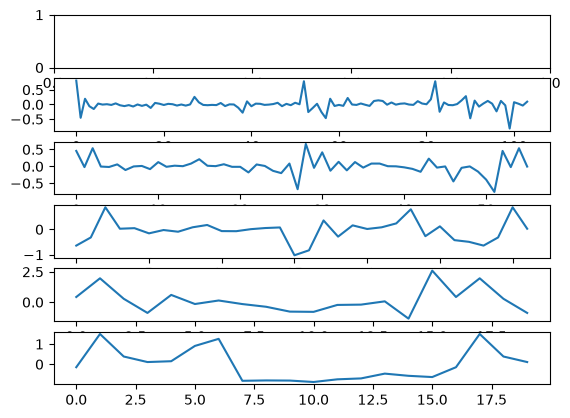

In [13]:
fig, axs = plt.subplots(nrows=6)
coeffs = pywt.wavedec(eagles_df['dif'].dropna(), 'db5', 4)

for ax, coeff in zip(axs.ravel()[::-1], coeffs):
    ax.plot(coeff)

<Axes: >

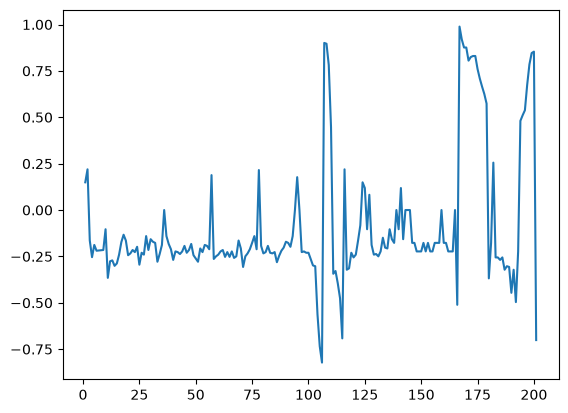

In [14]:
eagles_df['dif'].dropna().plot()

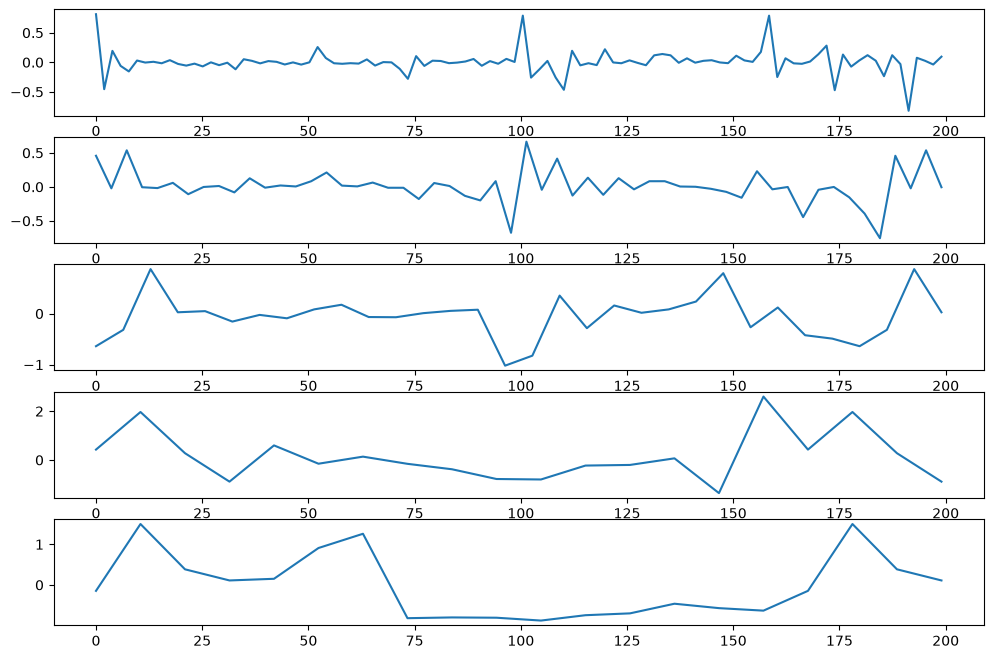

In [15]:
wavelet = 'db5'
level = 4

fig, axs = plt.subplots(nrows=level+1, figsize=(12, 8))
coeffs = pywt.wavedec(eagles_df['dif'].dropna(), wavelet, level)

for ax, coeff in zip(axs.ravel()[::-1], coeffs):
    max = eagles_df['dif'].dropna().shape[0]
    num = len(coeff)
    ax.plot(
        np.linspace(0, max, num=num),
        coeff
    )

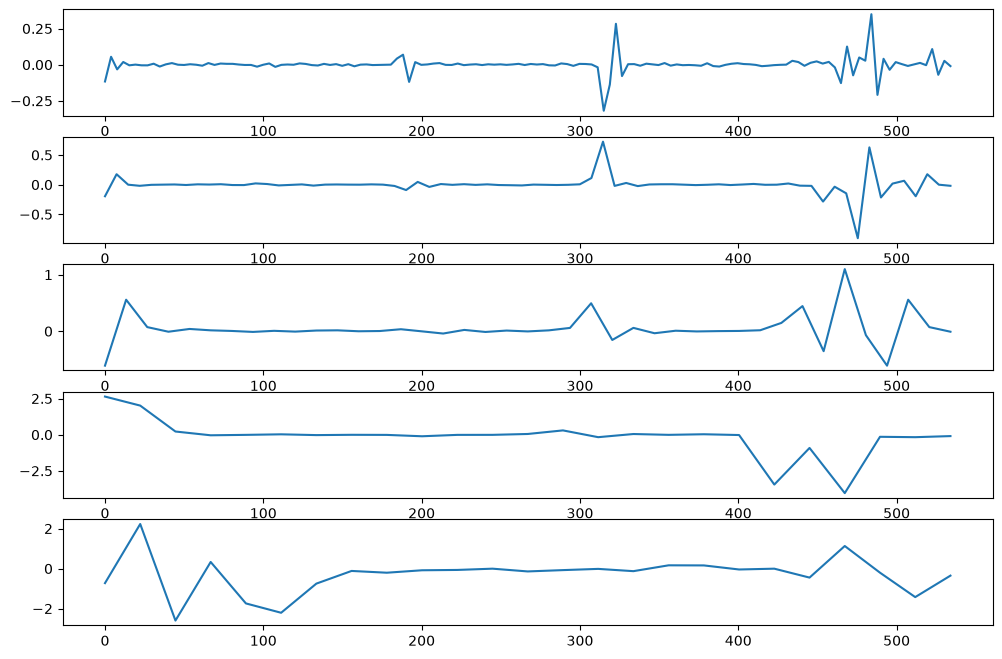

In [16]:
wavelet = 'db5'
level = 4

fig, axs = plt.subplots(nrows=level+1, figsize=(12, 8))
coeffs = pywt.wavedec(vezhen_df['dif'].dropna(), wavelet, level)

for ax, coeff in zip(axs.ravel()[::-1], coeffs):
    max = vezhen_df['dif'].dropna().shape[0]
    num = len(coeff)
    ax.plot(
        np.linspace(0, max, num=num),
        coeff
    )

In [17]:
all_vessel_df = pd.read_csv('../../data/Vessels_PositionReport_5min_25Dec2024_25Jan2025.csv')

210359000
255806257
255806513
354537000
374855000
374855000


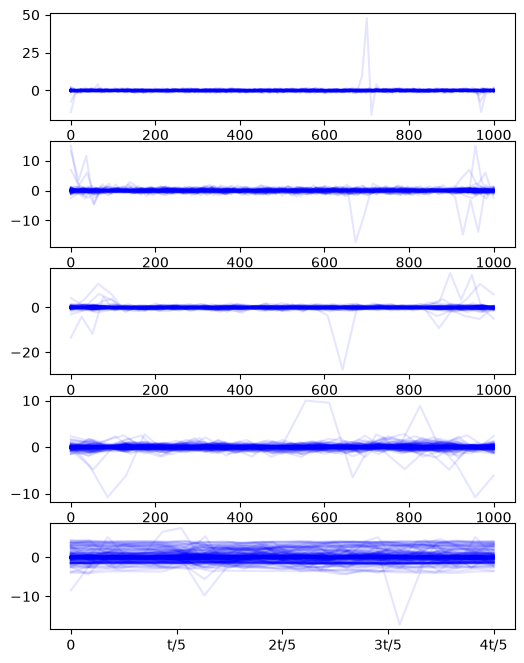

In [18]:
all_vessel_df['day'] = pd.to_datetime(all_vessel_df['DATE TIME (UTC)']).dt.date
fig, axs = plt.subplots(nrows=level+1, figsize=(6, 8))

for (mmsi, day), group_df in all_vessel_df.groupby(['MMSI', 'day']):
    group_df['DATE TIME (UTC)'] = pd.to_datetime(group_df['DATE TIME (UTC)'])
    group_df['date_diff'] = group_df['DATE TIME (UTC)'].diff(1) / timedelta(minutes=1)

    group_df = group_df\
        .set_index( 'DATE TIME (UTC)')\
        .resample('300s')\
        .first()\
        .dropna(subset=['MMSI'])\
        .reset_index()

    group_df['dif'] = ( group_df['HEADING'] - group_df['COURSE']  + 180) % 360 - 180
    group_df['dif'] = group_df['dif'] / group_df['date_diff']

    group_df = group_df[group_df['SPEED'] <= 25.0]
    group_df['dif'] = group_df['dif'] / 180 * 5

    wavelet = 'db5'
    level = 4

    coeffs = pywt.wavedec(group_df['dif'].dropna(), wavelet, level)

    print_mmsi = False
    for ax, coeff in zip(axs.ravel()[::-1], coeffs):
        x_axis = np.linspace(0, 1000, len(coeff))
        ax.plot(x_axis, coeff, alpha=0.1, color='blue')

        for c in coeff:
            if (c > 5).any():
                print_mmsi = True
        
        plt.xticks(
            ticks=np.linspace(0, 1000, 5),
            labels=['0', 't/5', '2t/5', '3t/5', '4t/5']
        )

    if print_mmsi:
        print(mmsi)

plt.show()

In [19]:
eagles_df['COURSE'] = ((eagles_df['COURSE'] + 180) %360 - 180)
eagles_df['COURSE'] = eagles_df['COURSE'] / 180

vezhen_df['COURSE'] = ((vezhen_df['COURSE'] + 180) %360 - 180)
vezhen_df['COURSE'] = vezhen_df['COURSE'] / 180

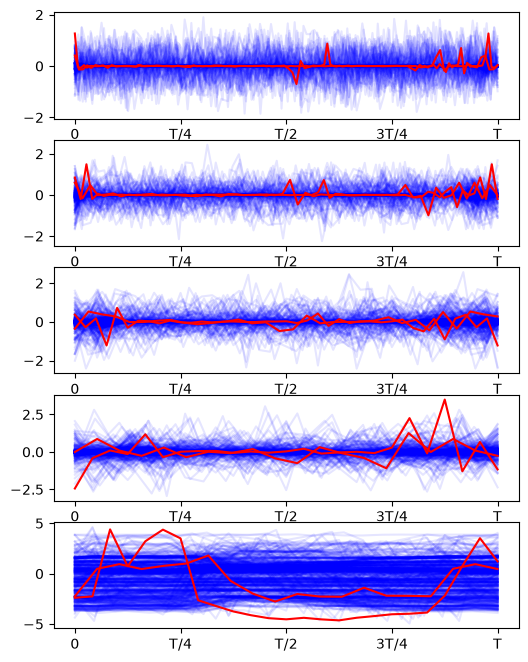

In [20]:
wavelet = 'db5'
level = 4

all_vessel_df['day'] = pd.to_datetime(all_vessel_df['DATE TIME (UTC)']).dt.date
fig, axs = plt.subplots(nrows=level+1, figsize=(6, 8))

for (mmsi, day), group_df in all_vessel_df.groupby(['MMSI', 'day']):

    if mmsi in [
        210359000,
        255806257,
        255806513,
        354537000,
        374855000
    ]:
        continue

    group_df['DATE TIME (UTC)'] = pd.to_datetime(group_df['DATE TIME (UTC)'])
    group_df['date_diff'] = group_df['DATE TIME (UTC)'].diff(1) / timedelta(minutes=1)

    group_df = group_df\
        .set_index( 'DATE TIME (UTC)')\
        .resample('300s')\
        .first()\
        .dropna(subset=['MMSI'])\
        .reset_index()

    group_df = group_df[group_df['SPEED'] <= 25.0]

    group_df['COURSE'] = ( group_df['COURSE']  + 180) % 360 - 180
    group_df['COURSE'] = group_df['COURSE'] / 180

    coeffs = pywt.wavedec(group_df['COURSE'].dropna(), wavelet, level)

    print_mmsi = False
    for ax, coeff in zip(axs.ravel()[::-1], coeffs):
        x_axis = np.linspace(0, 1000, len(coeff))
        ax.plot(x_axis, coeff, alpha=0.1, color='blue')
        
        ax.set_xticks(
            ticks=np.linspace(0, 1000, 5),
            labels=['0', 'T/4', 'T/2', '3T/4', 'T']
        )

for df in [vezhen_df, eagles_df]:
    coeffs = pywt.wavedec(df['COURSE'].dropna(), wavelet, level)

    for ax, coeff in zip(axs.ravel()[::-1], coeffs):
        x_axis = np.linspace(0, 1000, len(coeff))
        ax.plot(x_axis, coeff, color='red')
        
        ax.set_xticks(
            ticks=np.linspace(0, 1000, 5),
            labels=['0', 'T/4', 'T/2', '3T/4', 'T']
        )
        
plt.show()

In [21]:
from scipy.signal import ShortTimeFFT
from scipy.signal import windows

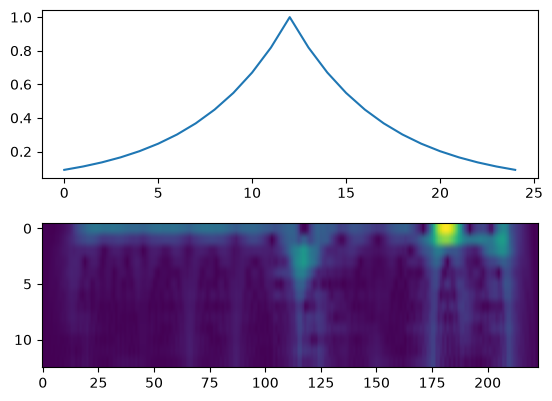

In [22]:
fig,axs = plt.subplots(nrows=2)

T_x = 1/5
w = windows.exponential(M=25, tau=5)
axs[0].plot(w)

Sx = ShortTimeFFT(w, hop=1, fs=1/T_x, scale_to='psd')\
    .stft(eagles_df['dif'].dropna().values)
axs[1].imshow( np.abs(Sx), aspect=5.0)

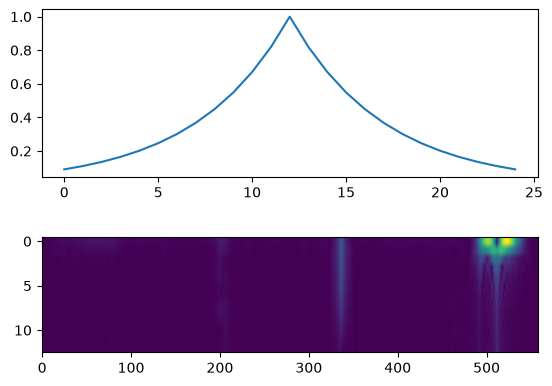

In [23]:
fig,axs = plt.subplots(nrows=2)

T_x = 1/5
w = windows.exponential(M=25, tau=5)
axs[0].plot(w)

Sx = ShortTimeFFT(w, hop=1, fs=1/T_x, scale_to='psd')\
    .stft(vezhen_df['dif'].dropna().values)
axs[1].imshow( np.abs(Sx), aspect=10.0)

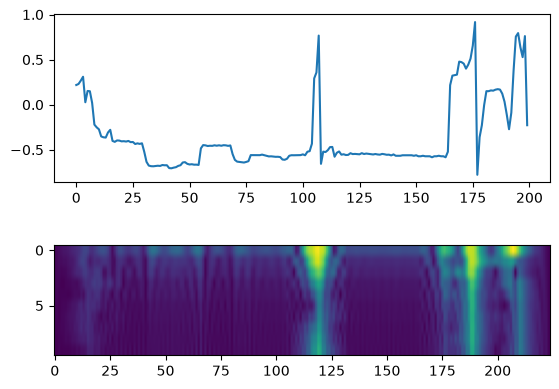

In [24]:
fig,axs = plt.subplots(nrows=2)

T_x = 1/5
w = windows.exponential(M=25, tau=5)
axs[0].plot(eagles_df['COURSE'].dropna().values)

Sx = ShortTimeFFT(w, hop=1, fs=1/T_x, scale_to='psd')\
    .stft(eagles_df['COURSE'].dropna().values)
axs[1].imshow( np.abs(Sx[3:, :]), aspect=5.0)

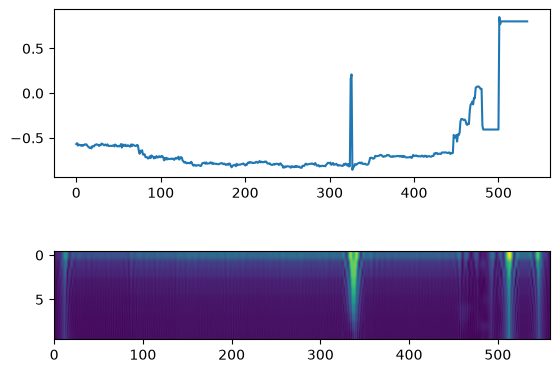

In [25]:
fig,axs = plt.subplots(nrows=2)

T_x = 1/5
w = windows.exponential(M=25, tau=5)
axs[0].plot(vezhen_df['COURSE'].dropna().values)

Sx = ShortTimeFFT(w, hop=1, fs=1/T_x, scale_to='psd')\
    .stft(vezhen_df['COURSE'].dropna().values)
axs[1].imshow( np.abs(Sx[3:, :]), aspect=10.0)

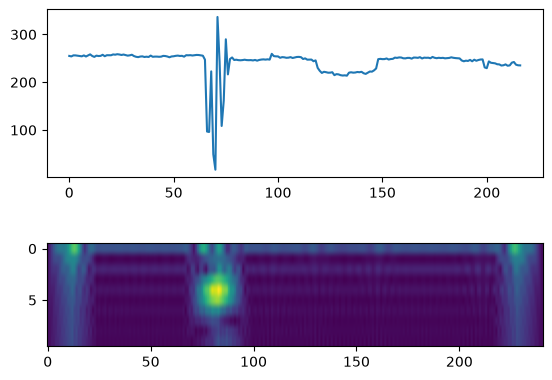

In [40]:
fig,axs = plt.subplots(nrows=2)

T_x = 1/5
# w = windows.exponential(25, tau=5)
w = windows.triang(25)

axs[0].plot(yipeng3_df['course'].dropna().values)
# axs[0].plot(yipeng3_df['dif'].dropna().values)

Sx = ShortTimeFFT(w, hop=1, fs=1/T_x, scale_to='psd')\
    .stft(yipeng3_df['course'].dropna().values)
axs[1].imshow( np.abs(Sx[3:, :]), aspect=5.0)

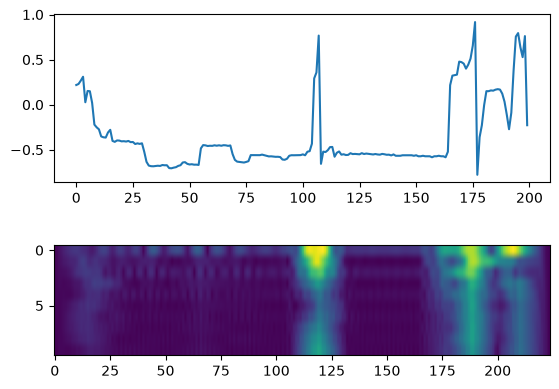

In [39]:
fig,axs = plt.subplots(nrows=2)

T_x = 1/5
# w = windows.exponential(25, tau=5)
w = windows.triang(25)

axs[0].plot(eagles_df['COURSE'].dropna().values)
# axs[0].plot(yipeng3_df['dif'].dropna().values)

Sx = ShortTimeFFT(w, hop=1, fs=1/T_x, scale_to='psd')\
    .stft(eagles_df['COURSE'].dropna().values)
axs[1].imshow( np.abs(Sx[3:, :]), aspect=5.0)

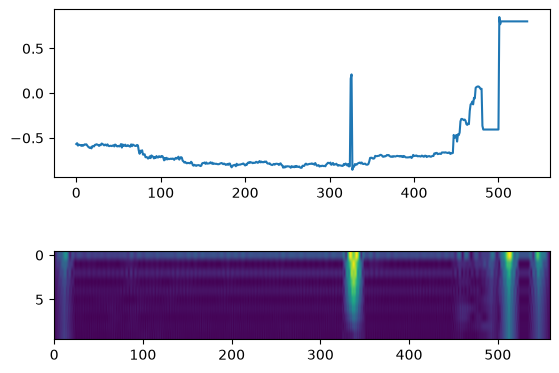

In [38]:
fig,axs = plt.subplots(nrows=2)

T_x = 1/5
# w = windows.exponential(25, tau=5)
w = windows.triang(25)

axs[0].plot(vezhen_df['COURSE'].dropna().values)
# axs[0].plot(yipeng3_df['dif'].dropna().values)

Sx = ShortTimeFFT(w, hop=1, fs=1/T_x, scale_to='psd')\
    .stft(vezhen_df['COURSE'].dropna().values)
axs[1].imshow( np.abs(Sx[3:, :]), aspect=10.0)

In [31]:
all_vessel_df['DATE TIME (UTC)'] = pd.to_datetime(all_vessel_df['DATE TIME (UTC)'])
all_vessel_df['day'] = all_vessel_df['DATE TIME (UTC)'].dt.date

for (mmsi, day), group_df in all_vessel_df.groupby(['MMSI', 'day']):
    if mmsi in [
        210359000,
        255806257,
        255806513,
        354537000,
        374855000
    ]:
        continue

    group_df['date_diff'] = group_df['DATE TIME (UTC)'].diff(1) / timedelta(minutes=1)

    group_df = group_df\
        .set_index( 'DATE TIME (UTC)')\
        .resample('300s')\
        .first()\
        .dropna(subset=['MMSI'])\
        .reset_index()

    group_df = group_df[group_df['SPEED'] <= 25.0]
    group_df = group_df[group_df['SPEED'] >= 1.0]

    group_df['COURSE'] = ( group_df['COURSE']  + 180) % 360 - 180
    group_df['COURSE'] = group_df['COURSE'] / 180

    if group_df['COURSE'].dropna().shape[0] < 50:
        continue

    T_x = 1/5
    w = windows.triang(25)

    fig, axs = plt.subplots(nrows=2)
    axs[0].plot(group_df['COURSE'].dropna().values)

    Sx = ShortTimeFFT(w, hop=1, fs=1/T_x, scale_to='psd')\
        .stft(group_df['COURSE'].dropna().values)
    axs[1].imshow( np.abs(Sx[3:, :]), aspect=10.0)

    fig.savefig(f'../images/spectros/mmsi-{mmsi}-day-{day}.png')
    plt.close(fig)

In [ ]:
for (mmsi, day), group_df in all_vessel_df.groupby(['MMSI', 'day']):

    if mmsi in [
        210359000,
        255806257,
        255806513,
        354537000,
        374855000
    ]:
        continue

    group_df['DATE TIME (UTC)'] = pd.to_datetime(group_df['DATE TIME (UTC)'])
    group_df['date_diff'] = group_df['DATE TIME (UTC)'].diff(1) / timedelta(minutes=1)

    if (group_df['date_diff'] > 120).any():
        continue

    group_df = group_df\
        .set_index( 'DATE TIME (UTC)')\
        .resample('300s')\
        .first()\
        .dropna(subset=['MMSI'])\
        .reset_index()

    group_df = group_df[group_df['SPEED'] <= 25.0]
    group_df = group_df[group_df['SPEED'] >= 1.0]

    group_df['COURSE'] = ( group_df['COURSE']  + 180) % 360 - 180
    group_df['COURSE'] = group_df['COURSE'] / 180 / group_df['date_diff'] * 5
    group_df['COURSE-diff'] = np.cbrt( group_df['COURSE'].diff(1) )

    T_x = 1/5
    w = windows.triang(25)

    if group_df['COURSE-diff'].dropna().shape[0] <= 50:
        continue

    fig, axs = plt.subplots(nrows=2)
    axs[0].plot(group_df['COURSE-diff'].dropna().values)

    Sx = ShortTimeFFT(w, hop=1, fs=1/T_x, scale_to='psd')\
        .stft(group_df['COURSE-diff'].dropna().values)
    axs[1].imshow( np.abs(Sx[3:, :]), aspect=10.0)

    fig.savefig(f'../images/spectros-cog-delta/mmsi-{mmsi}-day-{day}.png')
    plt.close(fig)